# LeafLens Part 3: Explainability with Grad-CAM
Needs `best.pt` (from Part 2) and `splits.json` (from Part 1). If the Part 2 runtime is still alive, the model is reused from memory.

## 1. Imports and model

In [ ]:
import json, numpy as np, torch, torch.nn as nn, torch.nn.functional as F
import matplotlib.pyplot as plt
from matplotlib import cm
from PIL import Image
from torchvision import models, transforms as T

device = "cuda" if torch.cuda.is_available() else "cpu"
MEAN, STD = [0.485, 0.456, 0.406], [0.229, 0.224, 0.225]

try:
    model, classes  # reuse from the Part 2 runtime if present
    print("reusing in-memory model")
except NameError:
    from google.colab import files
    files.upload()  # select best.pt and splits.json
    classes = json.load(open("splits.json"))["classes"]
    model = models.resnet50(weights=None)
    model.fc = nn.Linear(model.fc.in_features, len(classes))
    model.load_state_dict(torch.load("best.pt", map_location=device))

model = model.to(device).eval()
print(len(classes), "classes | device:", device)

Saving best.pt to best.pt
Saving splits.json to splits.json
38 classes | device: cuda


## 2. Grad-CAM (hooks on the last ResNet block, `layer4[-1]`)

In [ ]:
class GradCAM:
    def __init__(self, model, layer):
        self.model, self.acts, self.grads = model, None, None
        layer.register_forward_hook(self._fwd)

    def _fwd(self, module, inp, out):
        self.acts = out
        out.register_hook(lambda g: setattr(self, "grads", g))

    def __call__(self, x, class_idx=None):
        self.model.zero_grad()
        with torch.enable_grad():
            out = self.model(x)
            idx = out.argmax(1).item() if class_idx is None else class_idx
            out[0, idx].backward()
        w = self.grads.mean(dim=(2, 3), keepdim=True)            # channel importance
        cam = F.relu((w * self.acts.detach()).sum(1, keepdim=True))  # weighted sum of feature maps
        cam = F.interpolate(cam, size=x.shape[-2:], mode="bilinear", align_corners=False)[0, 0]
        cam = (cam - cam.min()) / (cam.max() - cam.min() + 1e-8)
        return cam.cpu().numpy(), idx, torch.softmax(out, 1)[0].detach().cpu()

cam_engine = GradCAM(model, model.layer4[-1])

show_pre = T.Compose([T.Resize(256), T.CenterCrop(224)])           # what the model sees (for display)
to_tensor = T.Compose([T.ToTensor(), T.Normalize(MEAN, STD)])
nice = lambda c: c.replace("___", ": ").replace("_", " ")
CONF_THRESHOLD = 0.70  # placeholder; tune on the validation set before using in the app

def explain(img, class_idx=None):
    crop = show_pre(img)
    x = to_tensor(crop).unsqueeze(0).to(device)
    cam, idx, probs = cam_engine(x, class_idx)
    heat = cm.jet(cam)[..., :3]
    over = np.clip(0.55 * np.asarray(crop) / 255.0 + 0.45 * heat, 0, 1)
    top = probs.topk(3)
    flag = "" if top.values[0] >= CONF_THRESHOLD else "  [LOW CONFIDENCE]"

    fig, ax = plt.subplots(1, 3, figsize=(15, 4.2), gridspec_kw={"width_ratios": [1, 1, 1.4]})
    ax[0].imshow(crop); ax[0].set_title("input"); ax[0].axis("off")
    ax[1].imshow(over); ax[1].set_title(f"{nice(classes[idx])}\n{probs[idx]:.1%}{flag}", fontsize=9); ax[1].axis("off")
    ax[2].barh([nice(classes[i]) for i in top.indices][::-1], top.values.numpy()[::-1])
    ax[2].set_xlim(0, 1); ax[2].set_title("top-3 predictions")
    plt.tight_layout(); plt.show()

## 3. Your own leaf photos (phone pictures, natural backgrounds)

In [ ]:
!git clone -q --depth 1 https://github.com/pratikkayal/PlantDoc-Dataset
!ls PlantDoc-Dataset

LICENSE.txt  PlantDoc_Examples.png  README.md  test  train


In [ ]:
!ls PlantDoc-Dataset/test

'Apple leaf'		    'Potato leaf late blight'
'Apple rust leaf'	    'Raspberry leaf'
'Apple Scab Leaf'	    'Soyabean leaf'
'Bell_pepper leaf'	    'Squash Powdery mildew leaf'
'Bell_pepper leaf spot'     'Strawberry leaf'
'Blueberry leaf'	    'Tomato Early blight leaf'
'Cherry leaf'		    'Tomato leaf'
'Corn Gray leaf spot'	    'Tomato leaf bacterial spot'
'Corn leaf blight'	    'Tomato leaf late blight'
'Corn rust leaf'	    'Tomato leaf mosaic virus'
'grape leaf'		    'Tomato leaf yellow virus'
'grape leaf black rot'	    'Tomato mold leaf'
'Peach leaf'		    'Tomato Septoria leaf spot'
'Potato leaf early blight'


2579 images found
Corn rust leaf | corn-southern-rust-2.jpg


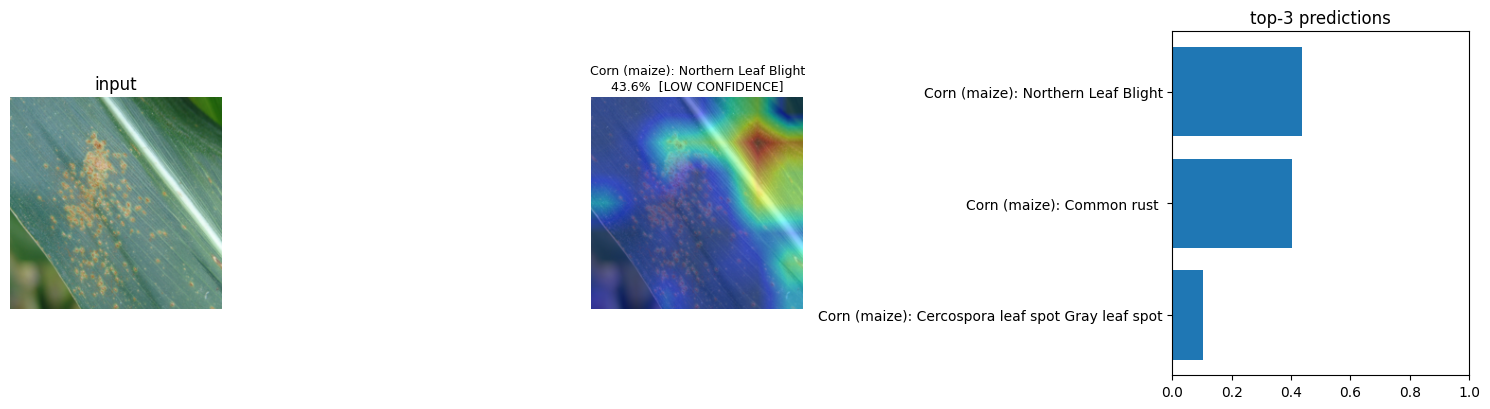

Apple rust leaf | cedar-apple-rust-gymnosporangium-juniperi-pustules-on-apple-leaf-lower-c99tfp.jpg


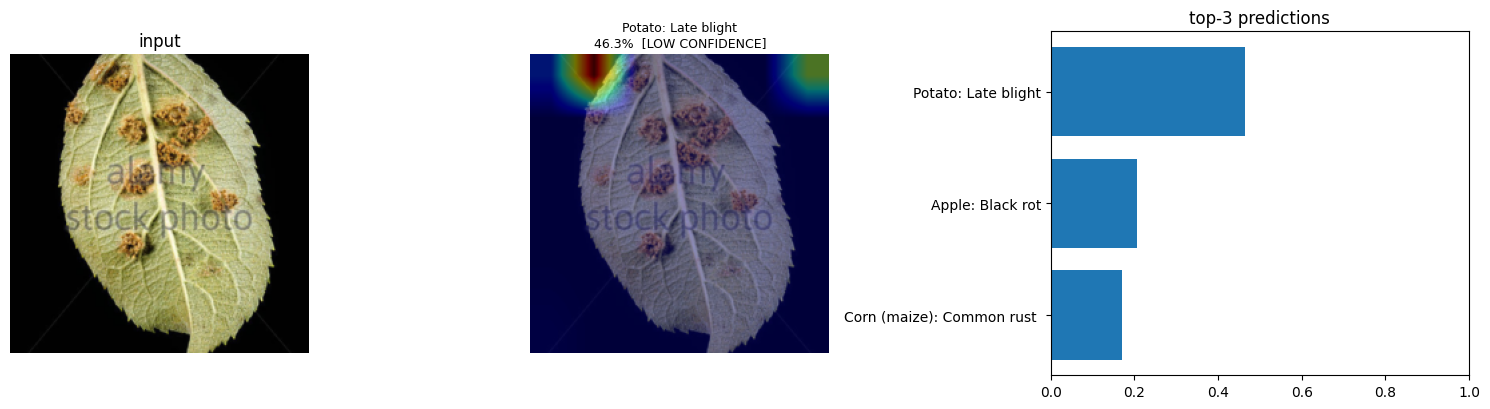

Tomato Early blight leaf | dscn3168.jpg


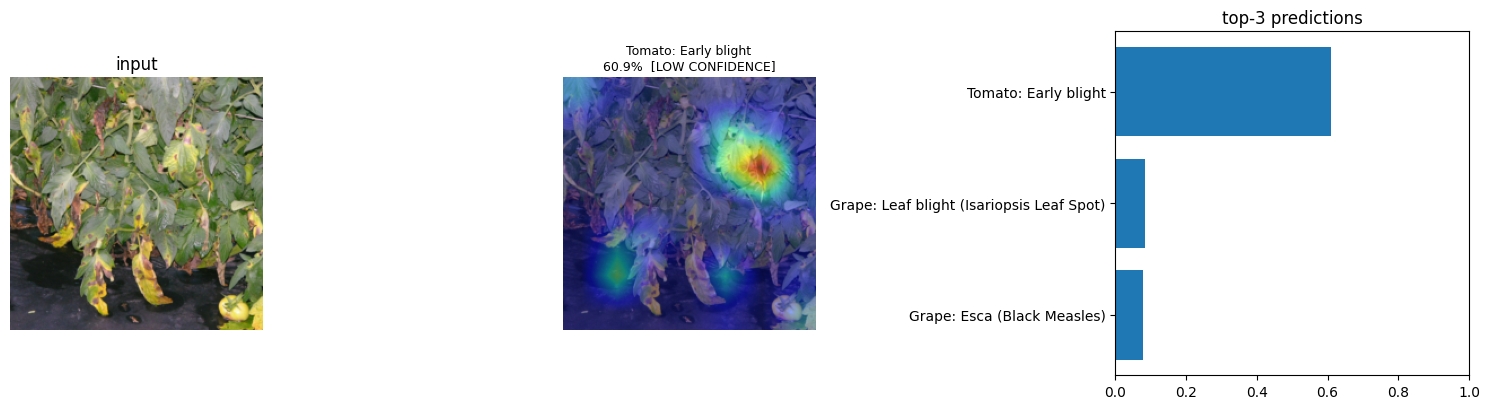

Raspberry leaf | a61a6-raspberry_leaf_tea_pregnancy.jpg


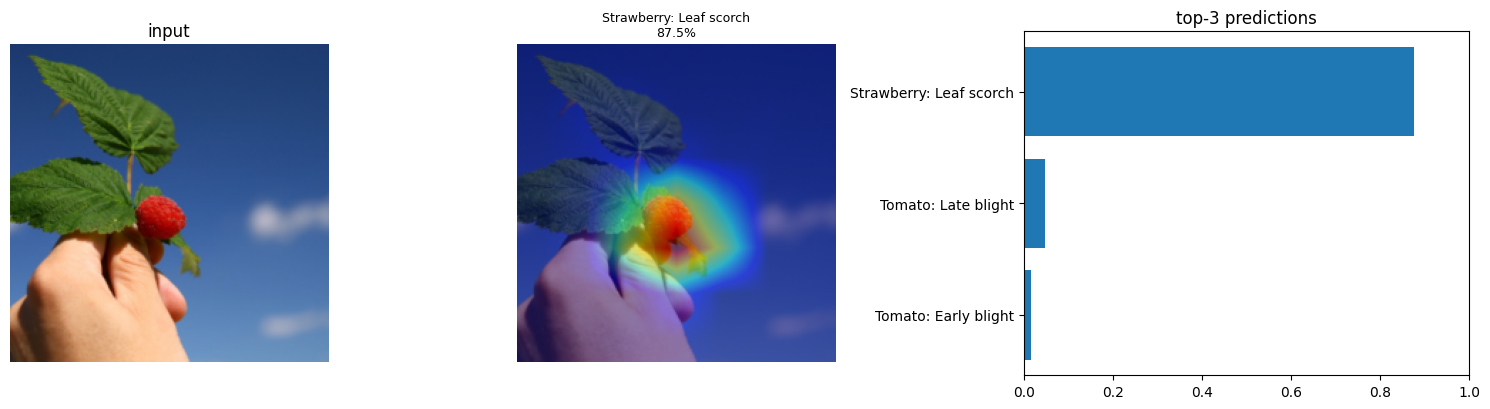

In [ ]:
import random
from pathlib import Path

imgs = [p for p in Path("PlantDoc-Dataset").rglob("*") if p.suffix.lower() in {".jpg", ".jpeg", ".png"}]
print(len(imgs), "images found")
random.seed(0)
for p in random.sample(imgs, 4):
    print(p.parent.name, "|", p.name)
    explain(Image.open(p).convert("RGB"))

In [ ]:
from google.colab import files
up = files.upload()
for name in up:
    print(name)
    explain(Image.open(name).convert("RGB"))

## 4. Failure gallery: where does the model look when it is wrong? (needs the Part 2 runtime)

In [ ]:
try:
    bad = np.where(preds != ys)[0][:4]
    print(len(np.where(preds != ys)[0]), "misclassified test images; showing", len(bad))
    for i in bad:
        print("TRUE:", nice(classes[ys[i]]))
        explain(Image.open(te_p[i]).convert("RGB"))
except NameError:
    print("Run Part 2 evaluation in this runtime first to use this cell.")

Run Part 2 evaluation in this runtime first to use this cell.


## 5.Checking everything


In [ ]:
from pathlib import Path
import pandas as pd

PD2PV = {  # PlantDoc folder -> PlantVillage class (substring, must match exactly one class)
    "Apple Scab Leaf": "Apple___Apple_scab",
    "Apple rust leaf": "Apple___Cedar_apple_rust",
    "Apple leaf": "Apple___healthy",
    "Bell_pepper leaf": "Pepper,_bell___healthy",
    "Bell_pepper leaf spot": "Pepper,_bell___Bacterial_spot",
    "Blueberry leaf": "Blueberry___healthy",
    "Cherry leaf": "Cherry_(including_sour)___healthy",
    "Corn Gray leaf spot": "Corn_(maize)___Cercospora",
    "Corn leaf blight": "Corn_(maize)___Northern_Leaf_Blight",
    "Corn rust leaf": "Corn_(maize)___Common_rust",
    "grape leaf": "Grape___healthy",
    "grape leaf black rot": "Grape___Black_rot",
    "Peach leaf": "Peach___healthy",
    "Potato leaf early blight": "Potato___Early_blight",
    "Potato leaf late blight": "Potato___Late_blight",
    "Raspberry leaf": "Raspberry___healthy",
    "Soyabean leaf": "Soybean___healthy",
    "Squash Powdery mildew leaf": "Squash___Powdery_mildew",
    "Strawberry leaf": "Strawberry___healthy",
    "Tomato Early blight leaf": "Tomato___Early_blight",
    "Tomato leaf": "Tomato___healthy",
    "Tomato leaf bacterial spot": "Tomato___Bacterial_spot",
    "Tomato leaf late blight": "Tomato___Late_blight",
    "Tomato leaf mosaic virus": "Tomato___Tomato_mosaic_virus",
    "Tomato leaf yellow virus": "Tomato___Tomato_Yellow_Leaf_Curl_Virus",
    "Tomato mold leaf": "Tomato___Leaf_Mold",
    "Tomato Septoria leaf spot": "Tomato___Septoria_leaf_spot",
}

def pv_idx(key):
    m = [i for i, c in enumerate(classes) if key in c]
    assert len(m) == 1, (key, m)
    return m[0]

pd_map = {k: pv_idx(v) for k, v in PD2PV.items()}
test_root = Path("PlantDoc-Dataset/test")
print("unmapped PlantDoc folders:", [d.name for d in test_root.iterdir() if d.is_dir() and d.name not in pd_map])

EXT = {".jpg", ".jpeg", ".png"}
samples = [(p, pd_map[d.name]) for d in sorted(test_root.iterdir()) if d.is_dir() and d.name in pd_map
           for p in sorted(d.iterdir()) if p.suffix.lower() in EXT]
print(len(samples), "PlantDoc test images")

tf = T.Compose([show_pre, to_tensor])

class PDSet(torch.utils.data.Dataset):
    def __len__(self):
        return len(samples)
    def __getitem__(self, i):
        p, y = samples[i]
        return tf(Image.open(p).convert("RGB")), y

dl = torch.utils.data.DataLoader(PDSet(), batch_size=64, num_workers=2)

model.layer4[-1]._forward_hooks.clear()  # Grad-CAM hook cannot run under no_grad
model.eval()
P, Y = [], []
with torch.no_grad():
    for x, y in dl:
        P.append(torch.softmax(model(x.to(device)), 1).cpu()); Y.append(y)
P, Y = torch.cat(P), torch.cat(Y)
top1, top3 = P.argmax(1), P.topk(3).indices
print(f"\nPlantDoc ({len(Y)} images, {len(pd_map)} classes mapped to PlantVillage): "
      f"top-1 {(top1 == Y).float().mean():.1%} | top-3 {(top3 == Y[:, None]).any(1).float().mean():.1%}")

rows = [(d, int((Y == y).sum()), (top1[Y == y] == y).float().mean().item()) for d, y in pd_map.items() if (Y == y).any()]
print(pd.DataFrame(rows, columns=["PlantDoc class", "n", "top-1 acc"]).sort_values("top-1 acc").to_string(index=False))

conf = P.max(1).values
print()
for t in (0.5, 0.7, 0.9):
    m = conf >= t
    print(f"confidence >= {t}: keeps {m.float().mean():.1%} of images, top-1 acc on those {(top1[m] == Y[m]).float().mean():.1%}")

cam_engine = GradCAM(model, model.layer4[-1])  # restore Grad-CAM for explain()


unmapped PlantDoc folders: []
236 PlantDoc test images

PlantDoc (236 images, 27 classes mapped to PlantVillage): top-1 22.9% | top-3 45.3%
            PlantDoc class  n  top-1 acc
                Apple leaf  9   0.000000
   Potato leaf late blight  8   0.000000
                Peach leaf  9   0.000000
  Tomato leaf mosaic virus 10   0.000000
               Tomato leaf  8   0.000000
Tomato leaf bacterial spot  9   0.000000
           Strawberry leaf  8   0.000000
             Soyabean leaf  8   0.000000
          Tomato mold leaf  6   0.000000
 Tomato Septoria leaf spot 11   0.090909
           Apple Scab Leaf 10   0.100000
  Potato leaf early blight  8   0.125000
Squash Powdery mildew leaf  6   0.166667
  Tomato leaf yellow virus  6   0.166667
               Cherry leaf 10   0.200000
           Apple rust leaf 10   0.200000
                grape leaf 12   0.250000
            Raspberry leaf  7   0.285714
     Bell_pepper leaf spot  9   0.333333
            Corn rust leaf 10   0.400000